# 02. EDA de la parte de train previa a la validación

In [1]:
import sys
from pathlib import Path
# La raíz del proyecto es la carpeta que contiene `src/` (funciona se ejecute desde la raíz o desde notebooks/)
RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))
RAIZ

WindowsPath('d:/OneDrive - SUPERINTENDENCIA DE BANCOS/Escritorio/Proyecto_final_ML/proyecto_final_ml_wti')

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA

import importlib

from src import config as cfg
import statsmodels.api as sm
from src import load_clean as lc
from src import eda_utils as eda
from src import download_data as dd
from src import preprocessing as pp

from pandas.tseries.holiday import USFederalHolidayCalendar, GoodFriday

In [5]:
out = RAIZ / "data" / "processed"
out.mkdir(parents=True, exist_ok=True)

In [6]:
base_ret = pd.read_csv(out / "train_validation.csv", index_col=0, parse_dates=True)
FOLDS    = pd.read_csv(out / "folds.csv", parse_dates=["train_ini", "train_fin", "val_ini", "val_fin"])

Las pruebas que orientan la elección del modelo base (estacionariedad, estacionalidad, ACF/PACF, Ljung-Box y ARCH-LM) se aplicarán al tramo enero 2010 – junio 2019, el cual corresponde al periodo de entrenamiento más corto de todos los folds (Rep 2 · Fold 1). 

Así, ninguna decisión de modelado usa información de los bloques de validación ni del test final.

In [7]:
EDA_FIN = FOLDS["train_fin"].min()          # = 2019-06-30, el train más corto
train_ret = base_ret.loc[:EDA_FIN]

print(f"Tramo de diagnóstico: {train_ret.index.min().date()} → {train_ret.index.max().date()} "
      f"({len(train_ret)} obs, {100*len(train_ret)/len(base_ret):.1f}% del desarrollo)")
assert train_ret.index.max() < FOLDS["val_ini"].min()   # no toca ninguna validación
train_ret

Tramo de diagnóstico: 2010-01-05 → 2019-06-28 (2385 obs, 63.3% del desarrollo)


,WTI,WTI_park
Date,,
2010-01-05,0.318465,0.599044
2010-01-06,1.709655,3.807394
2010-01-07,-0.627108,0.636423
2010-01-08,0.108816,1.473154
2010-01-11,-0.278337,2.075756
...,...,...
2019-06-24,0.815059,2.358784
2019-06-25,-0.120971,2.882069
2019-06-26,2.644978,1.681142


El tramo de diagnóstico (EDA) tiene un total de 2.385 observaciones, que representan el 63,3 % del conjunto de desarrollo (2010–2024).

Este período se utiliza para analizar el comportamiento histórico de las series financieras, identificar tendencias, volatilidad, estacionariedad, valores atípicos y relaciones entre variables, antes de realizar la validación temporal y el entrenamiento de los modelos predictivos.

## 2.1 Estadística Descriptiva

In [8]:
eda.descriptivos_precios(train_ret).T

serie,WTI,WTI_park
n,2385,2385
media,-0.013929,3.878855
std,2.049442,5.100214
CV,-147.132587,1.314876
min,-10.794222,0.128234
fecha_min,2014-11-28,2014-07-03
p25,-1.082266,1.173186
mediana,0.05218,2.25329
p75,1.095114,4.375953
max,11.621333,54.988894


El análisis descriptivo de los 2.385 log-retornos diarios del petróleo WTI de la parte de train seleccionada  correspondiente al período del 5 de enero de 2010 al 28 de junio de 2019, presenta los siguientes resultados:

- 	Rendimiento logarítmico promedio diario de aproximadamente -0,014 %, cercano a cero, con una ligera tendencia negativa.
- Volatilidad diaria de 2,05 %, que refleja la dispersión de los rendimientos respecto a su media.
- Mayor caída diaria observada, equivalente a un log-retorno de -10,79 % el 28 de Noviembre de 2014
- El 25 % de los rendimientos diarios fueron inferiores o iguales a -1,08 % en escala logarítmica.
- 	El 50 % de los rendimientos fueron inferiores o iguales a 0,052 %, evidenciando un rendimiento central ligeramente positivo.
- Mayor incremento diario observado, equivalente a un log-retorno de 11,62 % el 12 de Febrero de 2016.
- Asimetría (Skewness = -0,0171): indica que la distribución es prácticamente simétrica, con una ligera asimetría negativa. Por tanto, no se evidencia una inclinación significativa de la distribución hacia rendimientos negativos o positivos.
- Curtosis en exceso (2,9174): indica que la distribución es leptocúrtica, es decir, presenta colas más pesadas que una distribución normal, lo que sugiere mayor frecuencia de movimientos extremos.  Una distribución leptocúrtica significa que existe una mayor presencia de valores extremos (tanto negativos como positivos) en comparación con una distribución normal



## 2.2 Distribución, Estacionariedad, Estacionalidad y otras métricas

Para la estacionariedad se valida que:

- **ADF (Dickey Fuller Aumentada)**: $H_0$ = la serie tiene raíz unitaria (no estacionaria).
- **KPSS(Kwiatkowski-Phillips-Schmidt-Shin)**: $H_0$ = la serie es estacionaria.
- **PP (Philiphs-Perron)**:  $H_0$ = la serie tiene raíz unitaria (no estacionaria).

Se usan las dos porque tienen hipótesis nulas opuestas. La conclusión es fuerte cuando ambas coinciden.

In [10]:
eda.diagnostico_estacionariedad(train_ret[["WTI"]]).T

,0
serie,WTI
n,2385
ADF_stat,-34.4008
ADF_p,0.0
KPSS_stat,0.079
KPSS_p,0.1
PP_stat,-51.9578
PP_p,0.0
PP_lags,27


Los resultados sugieren que los retornos diarios del WTI en el conjunto de entrenamiento son estacionarios:

- ADF: estadístico = −34.40, p = 0.0 (redondeado por la salida). La prueba ADF tiene como hipótesis nula que la serie posee una raíz unitaria; el p-valor tan pequeño permite rechazarla (menor a 0.05).
- PP: estadístico = −52.95, p = 0.0 (redondeado por la salida). La prueba PP tiene como hipótesis nula que la serie posee una raíz unitaria; el p-valor tan pequeño permite rechazarla (menor a 0.05).
- KPSS: estadístico = 0.079, p = 0.1. La hipótesis nula de KPSS es que la serie es estacionaria; con ese p-valor no se rechaza (mayor a 0.05).

Como las tres pruebas apuntan en la misma dirección —ADF y PP rechazan no estacionariedad y KPSS no rechaza estacionariedad—, hay evidencia consistente de estacionariedad en train_ret.

La estacionalidad es la repetición de patrones en intervalos regulares de tiempo, como cambios que suelen ocurrir cada mes, trimestre o año. En una serie de retornos, puede reflejarse, por ejemplo, en que el retorno promedio varíe según el mes o en que exista dependencia entre observaciones separadas por un número fijo de períodos.

La prueba de Kruskal–Wallis compara varios grupos cuando no se quiere asumir que los datos siguen una distribución normal. En vez de comparar directamente las medias, ordena todas las observaciones de menor a mayor y compara los rangos entre grupos. En este caso, los grupos son los meses y los datos son los retornos del WTI de cada mes.

- Kruskal–Wallis — $H_{0}$: los grupos provienen de la misma distribución.




In [11]:
eda.diagnostico_estacionalidad(train_ret[["WTI"]]).T

,0
serie,WTI
n,2385
Kruskal_mes_p,0.504
ACF_5,0.0242
ACF_21,0.0016
ACF_252,0.0319


- Kruskal_mes_p = 0.504: p-valor de Kruskal–Wallis, que compara la distribución de los retornos entre meses. Como es mayor que 0.05, no se rechaza $H_{0}$; la prueba no encuentra evidencia de diferencias entre meses.
- ACF_5 = 0.0242, ACF_21 = 0.0016 y ACF_252 = 0.0319: autocorrelación de los retornos separados por 5, 21 y 252 observaciones, respectivamente. Son valores cercanos a cero, lo que sugiere poca relación lineal con los retornos de esos rezagos.

En conjunto, estos resultados no muestran evidencia clara de un patrón mensual ni de autocorrelación importante en esos rezagos.

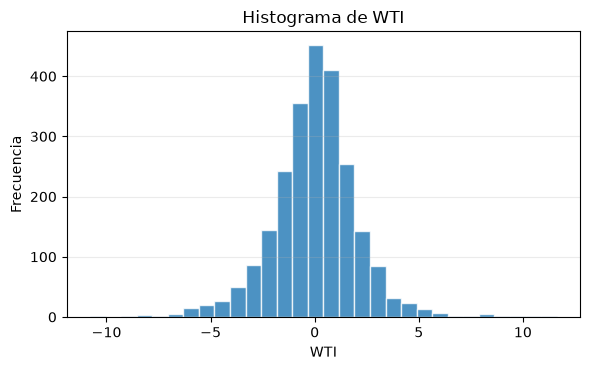

(<Figure size 600x380 with 1 Axes>,
 array([[<Axes: title={'center': 'Histograma de WTI'}, xlabel='WTI', ylabel='Frecuencia'>]],
       dtype=object))

In [12]:
eda.graficar_histograma(train_ret[["WTI"]])

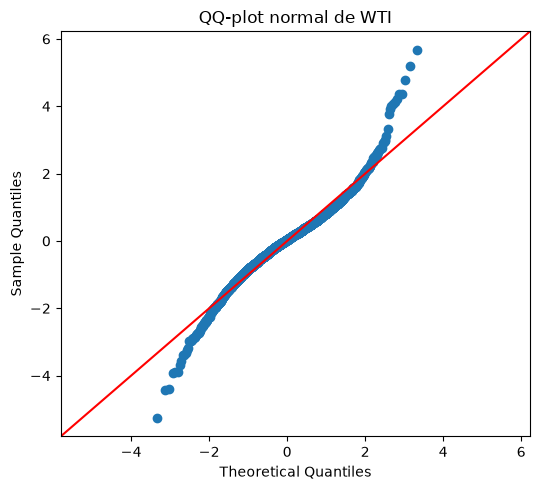

(<Figure size 550x500 with 1 Axes>,
 array([[<Axes: title={'center': 'QQ-plot normal de WTI'}, xlabel='Theoretical Quantiles', ylabel='Sample Quantiles'>]],
       dtype=object))

In [13]:
eda.graficar_qqplot(train_ret[["WTI"]])

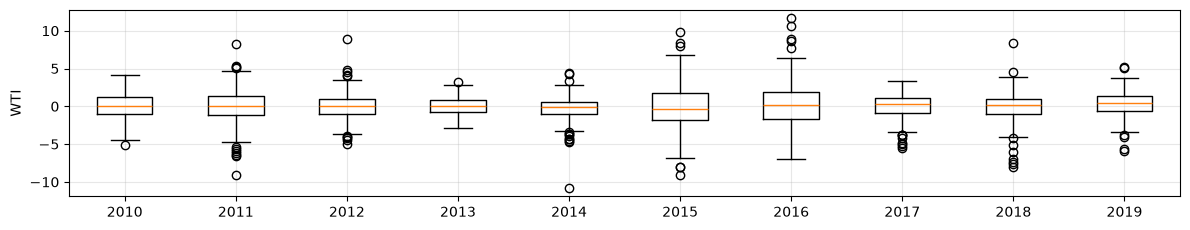

In [16]:
eda.graficar_boxplot_anual(train_ret[["WTI"]])

In [ ]:
### VER COLAS PESADAS

## 2.3 Dependencia temporal de los retornos

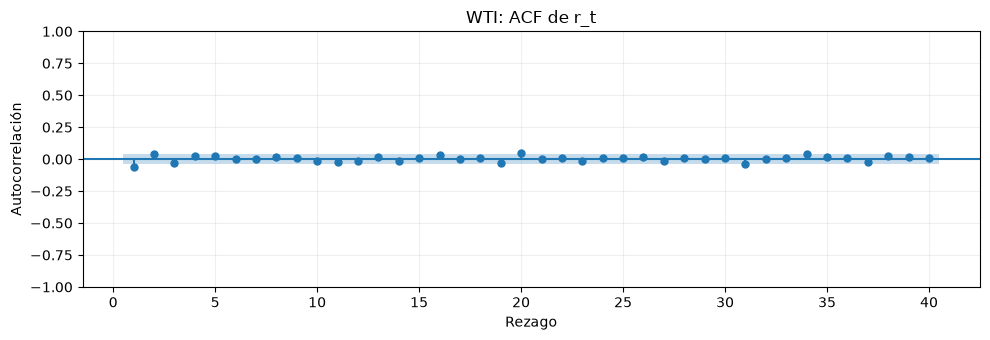

In [17]:
fig, axes, tabla_lb = eda.graficar_acf_con_pvalores(train_ret[["WTI"]])

Ljung–Box $H_{0}$: no existe autocorrelación conjunta en los retornos del WTI hasta el rezago evaluado.

In [18]:
tabla_lb.T

serie,WTI
n,2385.0000
LB_Q(5),18.5579
LB_p(5),0.0023
LB_Q(21),32.4203
LB_p(21),0.0531
LB_Q(252),297.2663
LB_p(252),0.0264


- Hasta el rezago 5: p-valor = 0.0023. Como es menor que 0.05, se rechaza $H_{0}$; hay evidencia de autocorrelación conjunta hasta ese rezago.
- Hasta el rezago 21: p-valor = 0.0531. Como es mayor que 0.05, no se rechaza $H_{0}$ al nivel de significancia del 5%.
- Hasta el rezago 252: p-valor = 0.0264. Como es menor que 0.05, se rechaza $H_{0}$; hay evidencia de autocorrelación conjunta hasta ese rezago.

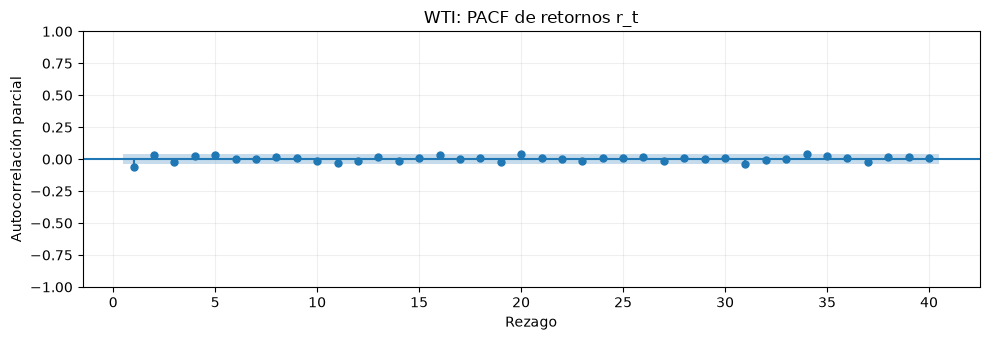

In [19]:
fig, axes, tabla_pacf = eda.graficar_pacf_con_pvalores(train_ret[["WTI"]])

Las autocorrelaciones parciales del gráfico son pequeñas y están cerca de cero, así que no se observa una relación directa fuerte entre los retornos actuales y los retornos pasados hasta el rezago 40, una vez controlados los rezagos intermedios.

In [20]:
display(tabla_pacf)

PACF  p_aprox
serie rezago                 
WTI   1      -0.0647   0.0016
      2       0.0342   0.0951
      3      -0.0246   0.2304
      4       0.0219   0.2847
      5       0.0293   0.1529
      6       0.0031   0.8778
      7      -0.0018   0.9281
      8       0.0142   0.4895
      9       0.0087   0.6724
      10     -0.0161   0.4305
      11     -0.0266   0.1935
      12     -0.0175   0.3931
      13      0.0167   0.4140
      14     -0.0130   0.5269
      15      0.0086   0.6728
      16      0.0354   0.0838
      17      0.0037   0.8556
      18      0.0075   0.7157
      19     -0.0240   0.2411
      20      0.0405   0.0480
      21      0.0060   0.7684
      22      0.0002   0.9923
      23     -0.0117   0.5667
      24      0.0058   0.7755
      25      0.0069   0.7353
      26      0.0177   0.3863
      27     -0.0107   0.6004
      28      0.0092   0.6522
      29      0.0004   0.9857
      30      0.0092   0.6516
      31     -0.0366   0.0740
      32     -0.0030   0.8837
      33      0.0050   0.8074
      34      0.0412   0.0442
      35      0.0216   0.2912
      36      0.0074   0.7190
      37     -0.0245   0.2308
      38      0.0200   0.3294
      39      0.0186   0.3643
      40      0.0081   0.6922

La tabla muestra la PACF y un p-valor aproximado para cada rezago individual del WTI:
- En el rezago 1, PACF = −0.0647 y p = 0.0016: hay evidencia de una autocorrelación parcial negativa, aunque pequeña.
- En los rezagos 20 y 34, los p-valores también son menores que 0,05 (0.0480 y 0.0442), pero sus coeficientes son pequeños: 0.0405 y 0.0412.
- Los p-valores de los demás rezagos visibles son mayores que 0,05; para ellos no hay evidencia suficiente de una PACF distinta de cero al nivel del 5%.
En términos prácticos, las asociaciones estimadas son débiles. Además, como se están evaluando 40 rezagos por separado, algunos p-valores pueden quedar por debajo de 0,05 solo por azar.

## 2.4 Dependencia temporal de la volatilidad

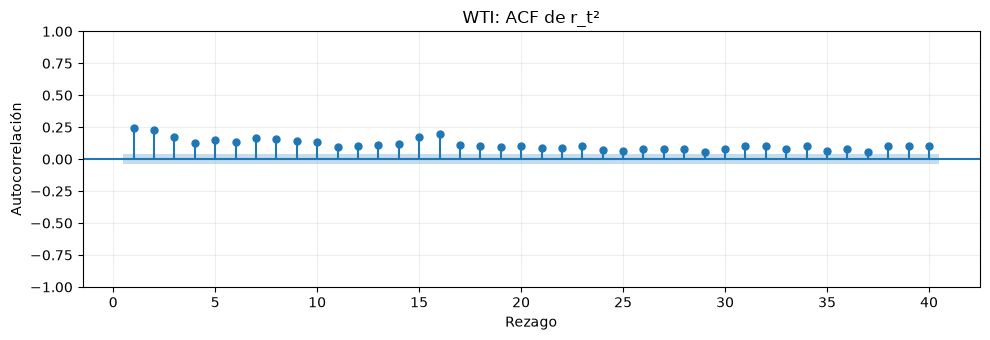

In [23]:
fig, axes, tabla_lb_r2 = eda.graficar_acf_con_pvalores(
    train_ret[["WTI"]].pow(2),
    etiqueta="r_t²"
)

In [24]:
tabla_lb_r2.T

serie,WTI
n,2385.0000
LB_Q(5),430.9515
LB_p(5),0.0000
LB_Q(21),1087.5299
LB_p(21),0.0000
LB_Q(252),2822.3607
LB_p(252),0.0000


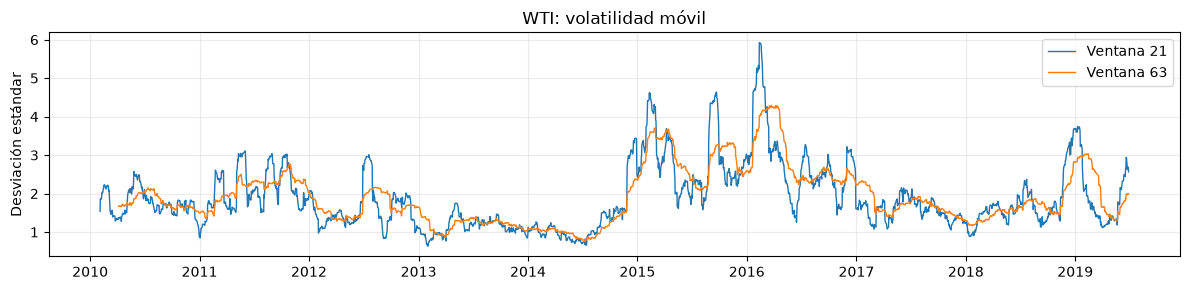

(<Figure size 1200x300 with 1 Axes>,
 array([<Axes: title={'center': 'WTI: volatilidad móvil'}, ylabel='Desviación estándar'>],
       dtype=object))

In [25]:
eda.graficar_volatilidad_movil(train_ret[["WTI"]], ventanas=(21, 63))

In [26]:
r = train_ret[["WTI"]].dropna()

modelo_media = ARIMA(r, order=(1, 0, 0), trend="c").fit()
residuos_media = modelo_media.resid


In [27]:
tabla_arch = eda.diagnostico_arch_lm(modelo_media.resid, lags=10)
tabla_arch.T

serie,serie
n,2385.0000
ARCH_LM_stat,296.4082
ARCH_LM_p,0.0000
ARCH_F_stat,33.7108
ARCH_F_p,0.0000
lags,10.0000


## 2.5 Conclusiones del EDA.

Qué indican los resultados
- Precios: la gráfica y los cambios de nivel sugieren que la serie de precios no es estacionaria. Sin embargo, en el notebook las pruebas ADF/KPSS/PP se aplicaron a train_ret, no a los precios. Para afirmar formalmente que el precio no es estacionario, faltaría aplicarles las pruebas a los niveles del precio.
- Retornos: ADF y PP reportan p = 0.0, y KPSS p = 0.1. Son valores redondeados: ADF y PP rechazan la hipótesis de raíz unitaria, y KPSS no rechaza la estacionariedad. La evidencia respalda modelar los retornos, que son estacionarios.
- Dependencia en la media: la ACF/PACF de los retornos es pequeña. Aun así, Ljung–Box da p = 0.0023 hasta el rezago 5 y p = 0.0264 hasta el 252, evidencia de autocorrelación conjunta débil. La PACF del rezago 1 es −0.0647 (p ≈ 0.0016); los resultados de los rezagos 20 y 34 son apenas significativos y deben tomarse con cautela porque se probaron 40 rezagos.
- Estacionalidad mensual: Kruskal–Wallis da p = 0.504; no encuentra evidencia de que la distribución de los retornos cambie entre meses. Esto no descarta toda forma de estacionalidad, pero no justifica añadir términos estacionales con la evidencia actual.
- Distribución: la asimetría es casi cero (−0.017), pero el exceso de curtosis es alto (2.917) y Jarque–Bera rechaza normalidad. Los retornos tienen colas más pesadas que una normal; una distribución t de Student es una opción razonable para probar.
- Dependencia en la volatilidad: la ACF de r_t² muestra dependencia conjunta muy significativa: Ljung–Box da p = 0.0000 hasta los rezagos 5, 21 y 252. Además, la volatilidad móvil presenta agrupamientos, y ARCH–LM sobre los residuos de la media AR(1) da p = 0.0000 con 10 rezagos. Esto es evidencia fuerte de efectos ARCH.

Como candidato inicial se propone AR(1)–GARCH(1,1) con errores t, comparándolo con modelos más simples mediante validación temporal.

In [28]:
base1=lc.load_raw()

In [29]:
base1

,WTI,WTI_High,WTI_Low
Date,,,
2010-01-04,81.510002,81.680000,79.629997
2010-01-05,81.769997,82.000000,80.949997
2010-01-06,83.180000,83.519997,80.849998
2010-01-07,82.660004,83.360001,82.260002
2010-01-08,82.750000,83.470001,81.800003
...,...,...,...
2026-10-26,101.760002,103.129997,100.330002
2026-10-27,99.900002,102.820000,99.440002
2026-10-28,102.779999,103.550003,99.750000


In [31]:
p = base1["WTI"].loc[:EDA_FIN]
dP = p.diff()
r  = 100 * np.log(p / p.shift(1))

comp = pd.DataFrame({
    "precio_medio": p.resample("YE").mean(),
    "std_diferencia_USD": dP.resample("YE").std(),
    "std_retorno_%": r.resample("YE").std(),
})
display(comp.round(2))
print("Corr(precio, std ΔP):", comp["precio_medio"].corr(comp["std_diferencia_USD"]).round(2))
print("Corr(precio, std r) :", comp["precio_medio"].corr(comp["std_retorno_%"]).round(2))

,precio_medio,std_diferencia_USD,std_retorno_%
Date,,,
2010-12-31,79.61,1.35,1.73
2011-12-31,95.11,2.05,2.20
2012-12-31,94.21,1.50,1.64
2013-12-31,98.05,1.13,1.15
2014-12-31,92.91,1.24,1.53
2015-12-31,48.76,1.42,2.96
2016-12-31,43.44,1.17,2.97
2017-12-31,50.85,0.79,1.59
2018-12-31,64.95,1.19,1.98


Corr(precio, std ΔP): 0.5
Corr(precio, std r) : -0.65
